# Predictions of interactions with SteadierCom for gut microbiome

In [1]:
import pandas as pd
import json
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.gridspec as gridspec
import re

import os
import sys


from scipy.stats import kendalltau

sys.path.append("../functions/")
sys.path.append("../functions/plot_steady_state_flux/")
import venturelli2018
import steadiercom_samples_plotting
import abundance_analysis.co_growth as abundance_sim_analysis
import abundance_analysis.venturelli2018 as venturelli2018_abund



In [2]:
%load_ext autoreload
%autoreload 2

### Functions

In [3]:
from itertools import product

def merge_smetana_steadiercom(smetana_results,steadiercom_results):
    """
    Function for creating donor-compound-receiver triplets for SMETANA and SteadierCom results. 
    
    Also assigns super_class

    Parameters
    -----------
    smetana_results (pd.DataFrame): Dataframe with SMETANA results
    steadiercom_results (pd.DataFrame): Dataframe with SteadierCom results

    Returns
    ----------
    merged_sim (pd.DataFrame): Dataframe with merged data from simulations.
    """

    # Remove environment
    steadiercom_subset = steadiercom_results.query("receiver != 'environment' & donor != 'environment'")[["receiver","compound","donor","community","frequency","mass_rate"]]

    merged_sim = pd.merge(left=smetana_results, right=steadiercom_subset, on=["receiver", "compound","donor","community"], how="outer")
    merged_sim["super_class"] = merged_sim.compound.map(agora_super_class_map)
    merged_sim["mass_rate*frequency"] = merged_sim.mass_rate*merged_sim.frequency

    merged_sim = merged_sim.loc[:,["donor","compound","receiver","community","frequency","mass_rate*frequency","smetana","super_class"]]
    
    return merged_sim


def make_metabolomics_triplets(metabolomics, exp_thresh=1):

    """
    Function for creating donor-compound-receiver triplets from metabolomics data.

    NB! This function shows all inferred interactions (even when the compound name cannot be translated to the AGORA database).
    """

    # Make df with all possible combination
    receiver_list = metabolomics.index.get_level_values("member").unique()
    donor_list = metabolomics.index.get_level_values("member").unique()
    compound_list = metabolomics.index.get_level_values("compound").unique()
    key_cols = ["receiver", "donor", "compound_name"]

    universe = pd.DataFrame(
        product(receiver_list, donor_list, compound_list),
        columns=key_cols
        )
    universe = universe.query("receiver != donor") # Remove self interactions

    ## Create triplets for metabolomics data
    # Filter by log change for finding consumers and producers of compounds 
    consumer = (
        metabolomics[metabolomics < -exp_thresh]
                .rename("consumer")
                .reset_index()[["compound","member"]]
                )
    producer = (
        metabolomics[metabolomics > exp_thresh]
                .rename("producer")
                .reset_index()[["compound","member"]]
                )


    # Find triplets from merging compound producer and consumer...
    exp_inter_df = (
        pd.merge(left=producer,right=consumer,on="compound",how="inner")
        .rename(columns={"member_x":"donor","member_y":"receiver"})
        )
    
    cols = ["compound","receiver","donor"]
    exp_inter_df = exp_inter_df[cols].rename(columns={"compound":"compound_name"})

    # combine with universal data
    exp_class_df = exp_inter_df.rename(columns={"compound":"compound_name"}).merge(universe, on=key_cols, how="outer", indicator=True)

    exp_class_df["exp_interact"] = exp_class_df["_merge"].map({
        "both": True,
        "right_only": False
    })
    exp_class_df = exp_class_df.drop(columns="_merge")

    return exp_class_df

def merge_metabolomics(merged_sim,exp_inter_df,metid2metname,sim_data_columns):
    """
    Function for labeling interactions predicted simulated data (steadiercom and smetana) based on inferred interactions from metabolomics data. 

    NB! This function keeps all simulated interactions (even when the compound has not been meassured in the metabolomics). 

    Parameters
    ----------
    merged_sim (pd.DataFrame): Dataframe with merged data from simulations.
    metabolomics (pd.DataFrame): Dataframe with metabolomics data
    metids_mapped (list): met IDs that could be mapped to metabolomics dataset.

    Returns
    ----------
    merged_sim_exp (pd.DataFrame): Dataframe with merged data from simulations and metabolomics.
    """

    ### NB! filter data###
    # Experimental data: only include compounds that could be mapped to simulated data. 
    exp_inter_df = exp_inter_df[exp_inter_df.compound_name.isin(metid2metname.values())].copy() # Only keep compounds that could be mapped to AGORA database.

    # Simulated data: Compound ID is mapped to compound name
    merged_sim = merged_sim.assign(compound_name=lambda x: x["compound"].map(metid2metname))

    # Merge exp triplets with sim triplets   
    merged_sim_exp = merged_sim.merge(exp_inter_df, on=["compound_name","receiver","donor"], how="outer", indicator=True)

    ### Clean up columns
    sim_missing = merged_sim_exp["_merge"].eq("right_only") # Identify missing simulations

    merged_sim_exp["compound"] = ( # fill in missing compound ids
        merged_sim_exp["compound"]
        .fillna(merged_sim_exp["compound_name"])
    )

    merged_sim_exp.loc[sim_missing, sim_data_columns] = 0 # fill in missing simulated data

    merged_sim_exp["experimental_support"] = np.select( # create experimental support column
        [
            merged_sim_exp["_merge"].eq("left_only"),
            merged_sim_exp["exp_interact"].eq(True),
            merged_sim_exp["exp_interact"].eq(False),
        ],
        [
            "met not measured",
            "supported",
            "not supported",
        ],
        default=pd.NA,
    )
    
    return merged_sim_exp.drop(["compound_name","exp_interact","_merge"], axis=1) # drop unnecessary columns

In [4]:
import matplotlib as mpl
from matplotlib.colors import TwoSlopeNorm
from matplotlib.gridspec import GridSpec
from matplotlib.collections import LineCollection

import compare_inter_exp_sim.venturelli2018 as venturelli2018_glv
import compare_inter_exp_sim.correlation as correlation
import compare_inter_exp_sim.general_funcs as general_glv

palette=mpl.colormaps["coolwarm"]

def process_simulation_results(simulation_res_all, signal_exp,method_comp=1):
    df_merged_list = []

    # Find the competition and cooperation results for each community
    for community, simulated_res in simulation_res_all.groupby("community"):

        # Find the cooperation results
        df_coop = general_glv.merge_exp_sim(simulated_res,
                                                signal_exp,
                                                coop_or_comp="coop",
                                                metric="frequency*mass_rate",
                                                verbose=True
                                                )
        # Find the competition results
        df_comp = general_glv.merge_exp_sim(simulated_res,
                                                signal_exp,
                                                coop_or_comp="comp",
                                                metric="frequency*mass_rate",
                                                verbose=True,
                                                method_comp=method_comp)
        df_merged = pd.merge(df_coop, df_comp.drop("experimental",axis=1),left_index=True,right_index=True, suffixes=("_coop", "_comp"))
        df_merged.loc[:,"community"] = community
        df_merged = df_merged.set_index("community",append=True)

        df_merged_list.append(df_merged)

    df_merged_unfiltered = pd.concat(df_merged_list,axis=0)
    return df_merged_unfiltered

def prepare_data(df_merged_unfiltered, glv_cutoff=1):
    df_merged = df_merged_unfiltered.copy().dropna() # NaN values is only for the A-A combinations and interactions with PC (not growing!)
    df_merged["exp_categories"] = pd.cut(df_merged["experimental"], bins=[-np.inf, -glv_cutoff, glv_cutoff, np.inf], labels=["negative", "neutral", "positive"])
    return df_merged

In [5]:

def plot_interactions(df_merged,title=""):

    # Normalize colors so that 0 is the center
    norm = TwoSlopeNorm(
        vmin=-3,
        vcenter=0,
        vmax=3
    )
    palette=mpl.colormaps["coolwarm"]

    fig = plt.figure(figsize=(10,8))

    gs = GridSpec(2, 2, width_ratios=[1, 2], height_ratios=[2, 1],)
    ax1 = fig.add_subplot(gs[0])
    ax2 = fig.add_subplot(gs[1])
    ax3 = fig.add_subplot(gs[2])
    ax4 = fig.add_subplot(gs[3])

    sns.scatterplot(ax=ax2,
                    data=df_merged,
                    x="simulated_coop",
                    y="simulated_comp",
                    hue="experimental",
                    palette=palette,
                    hue_norm=norm,
                    s=30
    )

    sns.move_legend(ax2, "upper left", bbox_to_anchor=(1.0, 1.0),title="gLV coefficient")


    sns.violinplot(df_merged,x="exp_categories",y="simulated_comp",hue="exp_categories",ax=ax1,palette="coolwarm",cut=0,alpha=0.8,linecolor="gray",inner_kws=dict(box_width=8, whis_width=1),zorder=0)
    sns.stripplot(df_merged,x="exp_categories",y="simulated_comp",hue="exp_categories",palette="coolwarm",ax=ax1,alpha=0.5,linewidth=0.5,edgecolor="gray",size=4,jitter=0.2,zorder=1)

    sns.violinplot(df_merged,y="exp_categories",x="simulated_coop",hue="exp_categories",ax=ax4,palette="coolwarm",cut=0,alpha=0.8,linecolor="gray",inner_kws=dict(box_width=8, whis_width=1),legend=True,zorder=0)
    sns.stripplot(df_merged,y="exp_categories",x="simulated_coop",hue="exp_categories",palette="coolwarm",ax=ax4,alpha=0.5,linewidth=0.5,edgecolor="gray",size=4,jitter=0.2,zorder=1)
    sns.move_legend(ax4, "upper left", bbox_to_anchor=(1.0, 1.0),title="gLV coefficient (categorical)")


    sns.kdeplot(signal_exp,
                ax=ax3
    )
    x, y = ax3.get_lines()[0].get_data()
    segments = np.array([x[:-1], y[:-1], x[1:], y[1:]]).T.reshape(-1, 2, 2)
    lc = LineCollection(segments, cmap='coolwarm', norm=norm)
    lc.set_array(x[:-1])
    lc.set_linewidth(2)
    ax3.get_lines()[0].remove()
    line = ax3.add_collection(lc)
    ax3.set_xlabel("gLV coefficient")

    
    ax2.set_xlabel("")
    ax2.set_ylabel("")

    ax1.set_xlabel("")
    ax4.set_ylabel("")

    fig.suptitle(title, fontsize=14)
    
    plt.show()
    


In [6]:
cmap_dict_overlap = {"met not measured":"#ffe599","not supported":"#b05ab4","supported":"#35af00"}

def plot_violin(merged,threshold=1e-6):

    threshold_main_classes = 0.15 # Min value of highest reported interaction score for compound

    main_metclasses_steadier = (
        merged.groupby("super_class")["frequency"]
        .max()
        .loc[lambda s: s > threshold_main_classes]
        .index
        .to_list()
    )

   # Find relevant met classes for smetana
    main_metclasse_smetana = (
        merged.groupby("super_class")["smetana"]
        .max()
        .loc[lambda s: s > threshold_main_classes]
        .index
        .to_list()
    )
   # Combine sets
    super_classes=list(set(main_metclasses_steadier+main_metclasse_smetana))

    # Get results for relevant classes only
    merged_copy = (
        merged[merged.super_class.isin(super_classes) ]
        ).copy()

    # Filter steadiercom and smetana results based on threshold
    merged_steadier = merged_copy.query("frequency > @threshold")
    merged_smetana = (
        merged_copy.query("smetana > @threshold")
        )
    
    assert "experimental_support" in merged_steadier.columns, f"experimental_support not in merged_steadier: {merged_steadier.columns}"
    assert "experimental_support" in merged_smetana.columns, f"experimental_support not in merged_smetana: {merged_smetana.columns}"



    # For each dataset -> count number of  in each categroy
    class_count = pd.DataFrame(
        {"freq_count": (
            merged_steadier.groupby("super_class")["frequency"]
            .count()
            ),
        "mus_count":(
            merged_smetana.groupby("super_class")["smetana"]
            .count()
            ) 
            }
    ).fillna(0).sort_values("freq_count",ascending=False)

    class_unique_count = pd.DataFrame(
        {"freq_count": (
            merged_steadier.groupby("super_class")["compound"]
            .nunique()
            ),
        "mus_count":(
            merged_smetana.groupby("super_class")["compound"]
            .nunique()
            ) 
            }
    ).fillna(0).sort_values("freq_count",ascending=False)

    hue_order = class_count.index
    
    fig = plt.figure(figsize =([12, 8]))
    gs = gridspec.GridSpec(2, 6)
    ax1a = plt.subplot(gs[:1, :2])
    ax1b = plt.subplot(gs[1, :2])
    ax2 = plt.subplot(gs[0, 2:])
    ax3 = plt.subplot(gs[1, 2:])
    alpha=0.6

    ax1a = class_count.T.plot.bar(color=metclass2color_dict,
                ax=ax1a,
                legend=None,
                alpha=alpha
                )
    ax1a.set_ylabel("Counts")
    ax1a.set_xticklabels(["frequency","SMETANA"])


    ax1b = class_unique_count.T.plot.bar(color=metclass2color_dict,
                ax=ax1b,
                legend=None,
                alpha=alpha
                )
    ax1b.set_ylabel("Unique Counts")
    ax1b.set_xticklabels(["frequency","SMETANA"])

    axs = [ax2,ax3]
    merged_list = [merged_steadier,merged_smetana]
    metric_list = ["frequency","smetana"]
    legend_list = [True, None]


    for ax,merged_spec,metric,legend in zip(axs,merged_list,metric_list,legend_list):
        merged_spec = merged_spec.sort_values("experimental_support")
        ax = sns.stripplot(merged_spec,
                    y=metric,
                    ax=ax,
                    x="super_class",
                    hue="experimental_support",
                    order=hue_order,
                    linewidth=0.,
                    legend=legend,
                    s=6,
                    alpha=0.5,
                    zorder=2,
                    palette=cmap_dict_overlap,
                    )
    
        ax = sns.boxplot(merged_spec,
                    y=metric,
                    ax=ax,
                    x="super_class",
                    hue="super_class",
                    order=hue_order,
                    linewidth=0.5,
                    legend=False,
                    zorder=1,
                    palette='dark:black',
                    fill=False,
                    fliersize=0,
                    medianprops={"color": "r", "linewidth": 0.5},
                    #whis=1.,
                    width=0.7,
                    )
    ax2.set_title("SteadierCom - frequency")
    ax2.set_xlabel("")
    ax2.set_xticklabels([])
    ax2.legend(loc='upper left', bbox_to_anchor=(1.0, 1),title="Metabolite class")  
    
    ax3.set_title("SMETANA")
    ax3.set_xlabel("Metabolite class")
    ax3.set_ylabel("SMETANA")
    ax3.tick_params(axis='x', rotation=90)
    #ax3.set_xticklabels([])
    plt.tight_layout()

    return fig,(ax1a,ax1b,ax2,ax3)

##### Previous functions

## Load data

In [7]:
met_chebi_class= pd.read_csv("../data/met_chebi_class.tsv",sep="\t",index_col=0)
extract = lambda s: s[s.index("_")+1:s.rindex("_")]

met_chebi_class.index = met_chebi_class.index.map(extract)
met_chebi_class.rename_axis("bigg_id",axis=0,inplace=True)

#### Simulation results

**Loading data for *full community* for different tools**

**Load data for *all communities* for steadiercom and smetana**

In [8]:
# load data for all communities (done separately, because the original method only imports the nan value)
df_res = []
for file in os.listdir("../output/Venturelli2018/results_steadiercom_no_proteome/results_growth_abundance/"):
    if file.endswith(".tsv"):
        df = pd.read_csv(f"../output/Venturelli2018/results_steadiercom_no_proteome/results_growth_abundance/{file}", sep="\t")
        df_res.append(df)

smetana_all = pd.read_csv("../output/Venturelli2018/smetana/no_coupling_detailed.tsv",sep="\t")

steadiercom_results_all = pd.concat(df_res, axis=0)
steadiercom_results_all["frequency*mass_rate"] = steadiercom_results_all.frequency*steadiercom_results_all.mass_rate 
steadiercom_results_all["frequency*rate"] = steadiercom_results_all.frequency*steadiercom_results_all.rate

# change to species abbreviation
steadiercom_results_all = venturelli2018._name_mapping(steadiercom_results_all)
smetana_all = venturelli2018._name_mapping(smetana_all)


#### Experimental data

**abundance**

In [9]:
experimental_abundance = pd.read_csv("../data/Venturelli2018/generated/communities_steadiercom/NONE_abundance.tsv",sep="\t",header=None)
experimental_abundance.columns = ["community", "member", "relative_abundance"]
experimental_abundance.member = experimental_abundance.member.map(lambda x: x.split("_")[0][0].upper()+x.split("_")[1][0].upper())

**metabolomics**

In [10]:
# Load dataset for log-change in concentration
metabolomics = pd.read_excel("../data/Venturelli2018/msb178157-sup-0005-datasetev4.xlsx",sheet_name="Dataset EV4",index_col=0)

# Adjust name of metabolites
metabolomics.index = metabolomics.index.map(lambda met: met.replace("'", "").replace(" ", "").lower())

# Adjust name of member
metabolomics.columns = metabolomics.columns.map(lambda x: x.replace("'","").replace(" ",""))
metabolomics.columns.name="member"
metabolomics.index.name="compound"
metabolomics.name="log-change"
metabolomics = metabolomics.stack()


In [11]:
len(metabolomics.index.get_level_values(0).unique())


97

**glv-coefficients**

In [12]:
signal_exp = venturelli2018_glv.load_experimental_results()

#### Other data

In [13]:
# Load metid2metname dict
with open("../data/Venturelli2018/generated/metid2metname.json",'r') as file:
    metid2metname = json.load(file)
metids_mapped = metid2metname.keys()
# Load: 1. chebi-agora map file and 2. experimental abundance file
metclass2color_dict = {"carbohydrate derivatives":"#DEFD3C",
            "amino acids and derivatives":"#ddaa7b",  
            "nucleotides and derivatives":"#fbdc5d",
            "oligosaccharides":"#8BBDAA",
            "oligopeptides":"#FFD19B",
            "simple sugars":"#9BF276", 
            "urea and urea derivatives":"#FFFFBA",
            "gases":"#b1fbf6", 
            "B-vitamins":"#6F7FB0", 
            "fatty acids":"#ffd1fd",  
            "carboxylic acids and anions":"#EB857E",
            "alcohols and aldehydes":"#C3BBF3", 
            "lipids":"#8FCFFF", 
            "cofactors":"#FF85A1",
            "other":"#eaeaea"
            }

met_chebi_class_agora = pd.read_csv("../data/Venturelli2018/generated/met_chebi_class_agora.tsv",sep="\t",index_col=0)
met_chebi_class_agora["self defined super class"] = met_chebi_class_agora["self defined super class"].map(lambda x: x if x in metclass2color_dict.keys() else "other")
agora_super_class_map = met_chebi_class_agora["self defined super class"].to_dict()

# Colormaps
cmap = ['#a6cee3','#1f78b4', '#b2df8a', '#33a02c', '#fb9a99','#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#6a3d9a', '#ffff99', '#b15928']
member2color_dict = dict(zip(experimental_abundance.sort_values("member").member.values,cmap))

## Interactions (flux) - SteadyCom vs SteadierCom


#### Fixed growth and abundance
*Description*: bar plots and circos plots

*Main target*
- These plots are made for illustrating the SteadierCom predictions of the steady-state metabolic phenotype.
- Show difference between SteadyCom and SteadierCom: How relative abundance affects predicted in mass flux between members

*TO-DO*
- Adapt the code for the enrichment cultures to the current case studies.

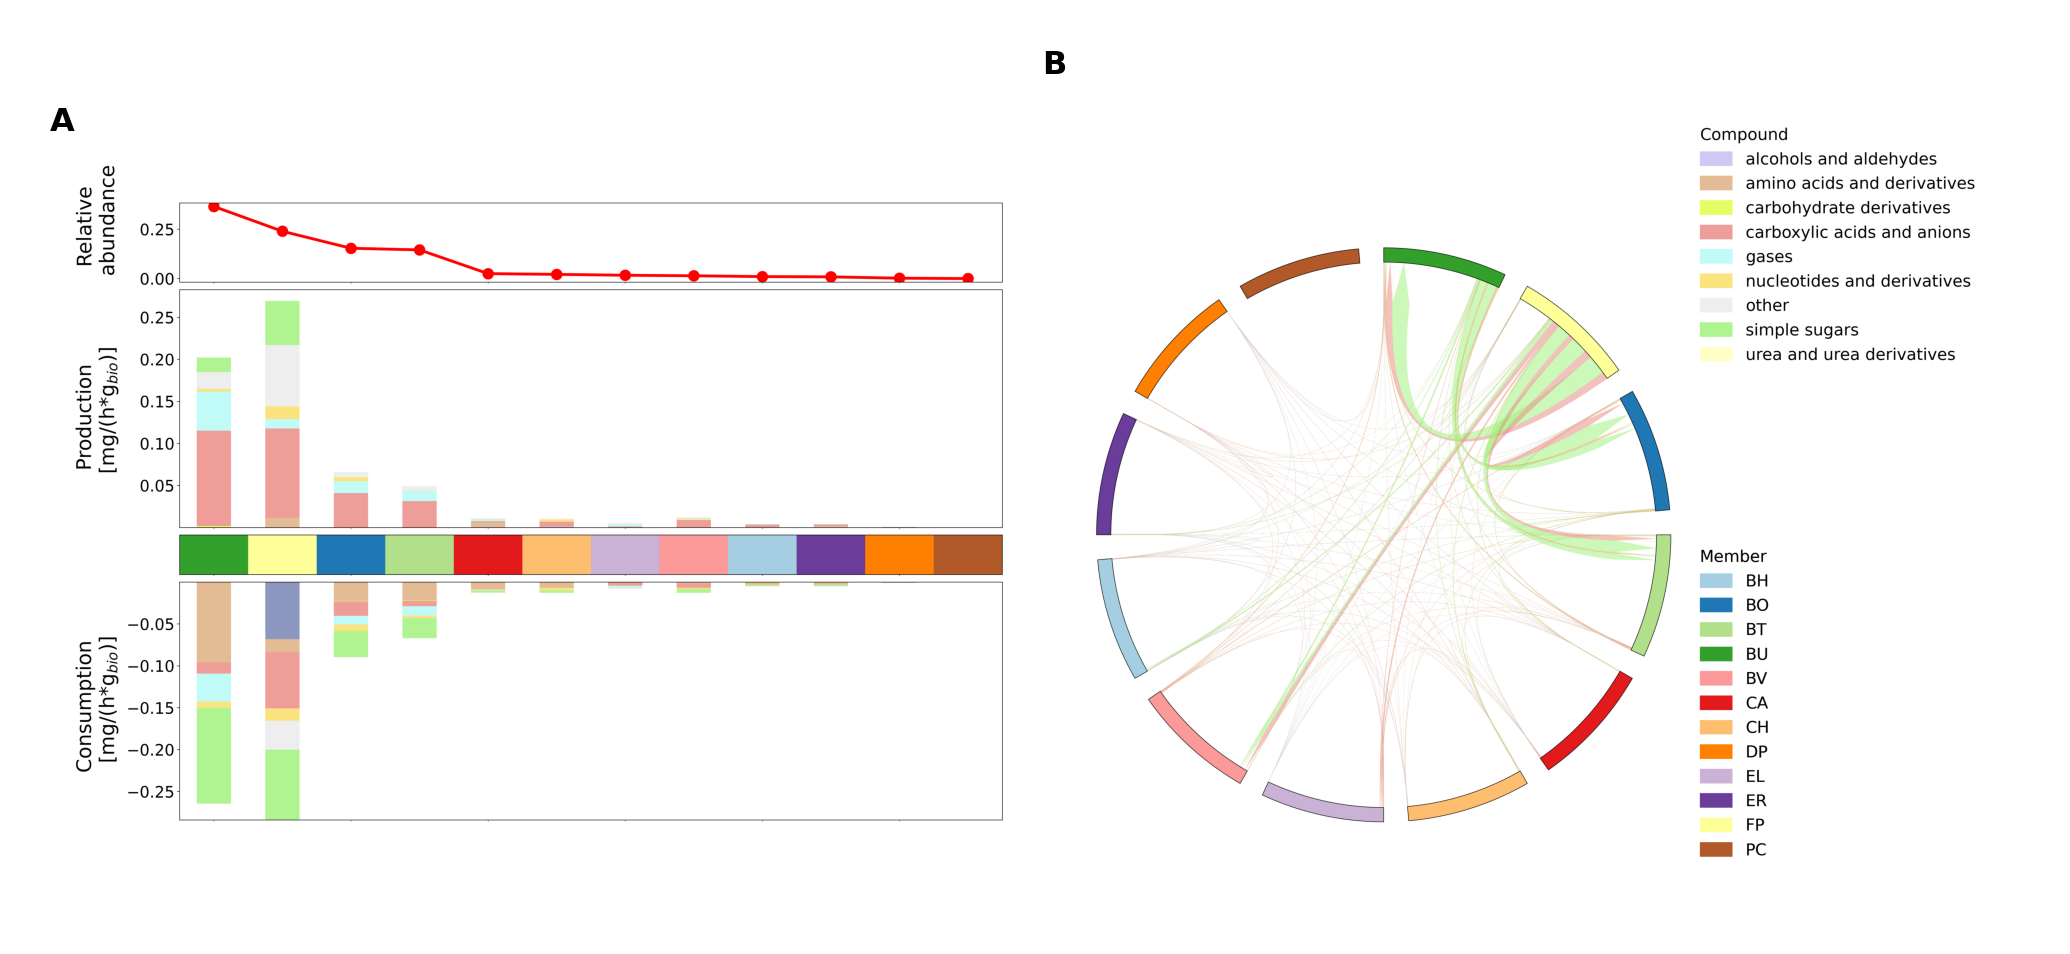

In [ ]:
sim_results = steadiercom_results_all.query("community == 'NONE'").copy()
sim_results["super_class"] = sim_results["compound"].map(agora_super_class_map)

sim_results["mass_rate*frequency"] = sim_results.mass_rate*sim_results.frequency 
sim_inter_res = sim_results.query("receiver != 'environment' & donor != 'environment'")

steadiercom_samples_plotting.combined_figure(sim_results,experimental_abundance,member2color_dict,"NONE",path = "../figures/circos/no_proteome_",move_legend=0)

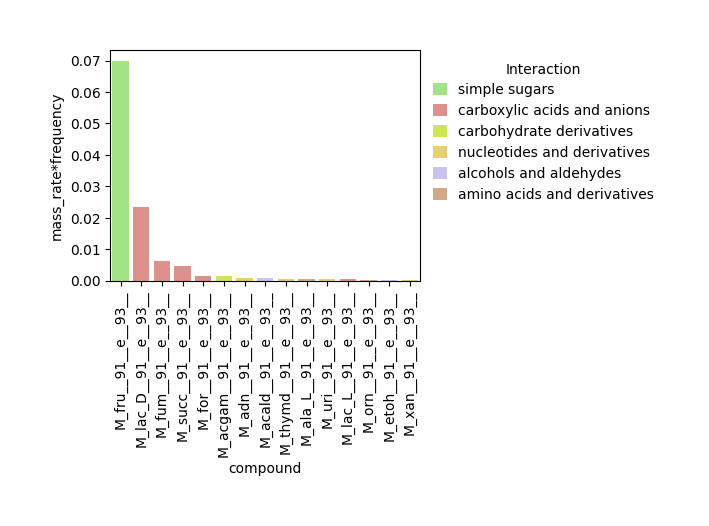

In [15]:
df = (
    sim_inter_res
    .groupby(by=["super_class","compound"])["mass_rate*frequency"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
    )


fig,ax = plt.subplots(1,1,figsize=(4,3))
sns.barplot(df.head(15),x="compound",y="mass_rate*frequency",hue="super_class",palette=metclass2color_dict,ax=ax)

ax.tick_params(axis='x', rotation=90)

sns.move_legend(ax, "upper left",title="Interaction" ,bbox_to_anchor=(1.0, 1.0),)

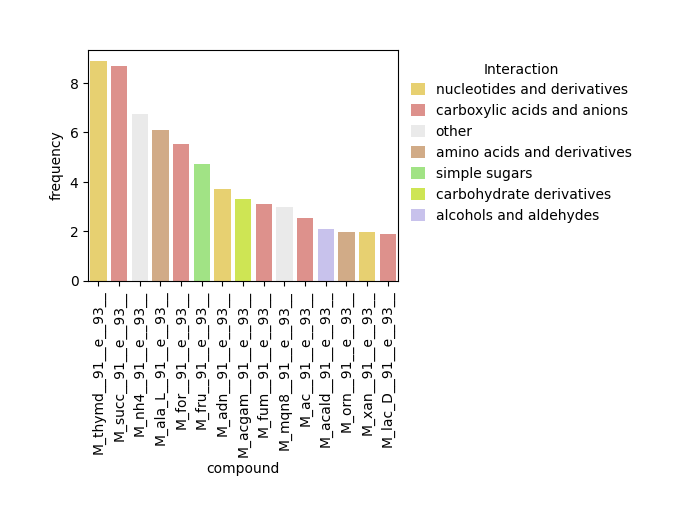

In [16]:
df = (
    sim_inter_res
    .groupby(by=["super_class","compound"])["frequency"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
    )

fig,ax = plt.subplots(1,1,figsize=(4,3))
sns.barplot(df.head(15),x="compound",y="frequency",hue="super_class",palette=metclass2color_dict,ax=ax)

ax.tick_params(axis='x', rotation=90)

sns.move_legend(ax, "upper left",title="Interaction" ,bbox_to_anchor=(1.0, 1.0),)

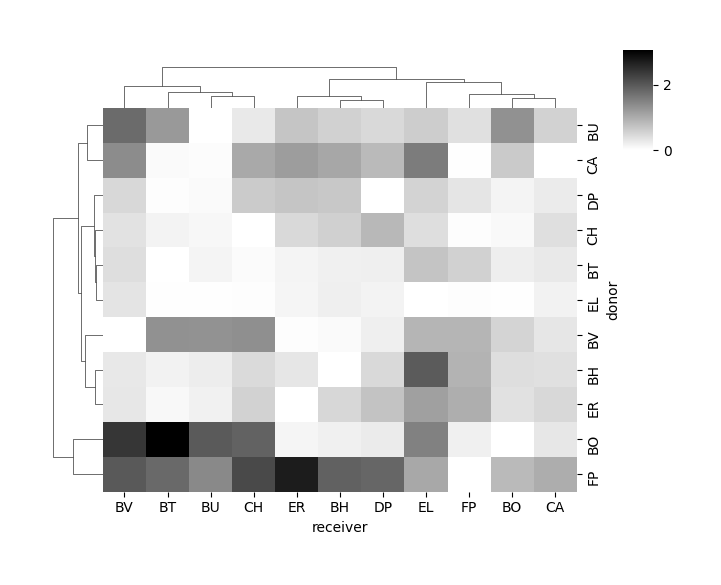

In [17]:
df = (
    sim_inter_res
    .groupby(by=["donor","receiver"])["frequency"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
    )
df2 = df.pivot_table(index=["receiver"],columns=["donor"],values="frequency").fillna(0)

sns.clustermap(df2.T,cmap="binary",method="ward",figsize=(6,5),dendrogram_ratio=0.1,cbar_pos=(0.98,0.8,0.05,0.2),)

### SteadierCom vs SteadyCom: Proteome constraints constrain the metabolic fluxes 
*Description*: Scatter plot of aggregate fluxes in SteadierCom and SteadyCom

*Main target*: Show how the fluxes are more constrained in SteadierCom

## Interactions (frequency) - SMETANA vs SteadierCom

*Description*: Compare with experimental results?? (For the flux prediction we don't really have experimental data for comparison, but here we kindoff do)

*Main target*: Show the difference between predicted important reactions in SMETANA and SteadierCom - for SteadierCom focus on frequency

**Process metabolomics data**

In [18]:
exp_thresh = 0.5
signal_exp_df = make_metabolomics_triplets(metabolomics,exp_thresh=exp_thresh)

**combine simulated data**

In [19]:

smetana_results = smetana_all.copy()
steadiercom_results = steadiercom_results_all.copy()
merged_sim = merge_smetana_steadiercom(smetana_results,steadiercom_results)

**Calculate statistics**

In [20]:
# Prepare for calculating statistics: fill in missing values in simulated data (ensure all communities are represented with the same interactions)
sim_wide = merged_sim.pivot_table(
    index=["donor", "compound", "receiver"],
    columns="community",
    values=["frequency", "smetana"],
    fill_value=0,
)

# Calculate statistics around median value
df_stats = (
    pd.DataFrame({
        "steadiercom_median": sim_wide["frequency"].median(axis=1),
        "steadiercom_q25":    sim_wide["frequency"].quantile(0.25, axis=1),
        "steadiercom_q75":    sim_wide["frequency"].quantile(0.75, axis=1),

        "smetana_median":      sim_wide["smetana"].median(axis=1),
        "smetana_q25":         sim_wide["smetana"].quantile(0.25, axis=1),
        "smetana_q75":         sim_wide["smetana"].quantile(0.75, axis=1),
    })
    .reset_index()
)

# Annotate with the experimental data (met not measured, supported, not supported)
sim_data_columns = ["steadiercom_median","steadiercom_q25","steadiercom_q75","smetana_median","smetana_q25","smetana_q75"]
df_merge = merge_metabolomics(
    df_stats,
    signal_exp_df,
    metid2metname,
    sim_data_columns
)

### Per compound-class analysis: donor-compound-receiver (Triplets)

#### Scatterplot - overlap with metabolomics data

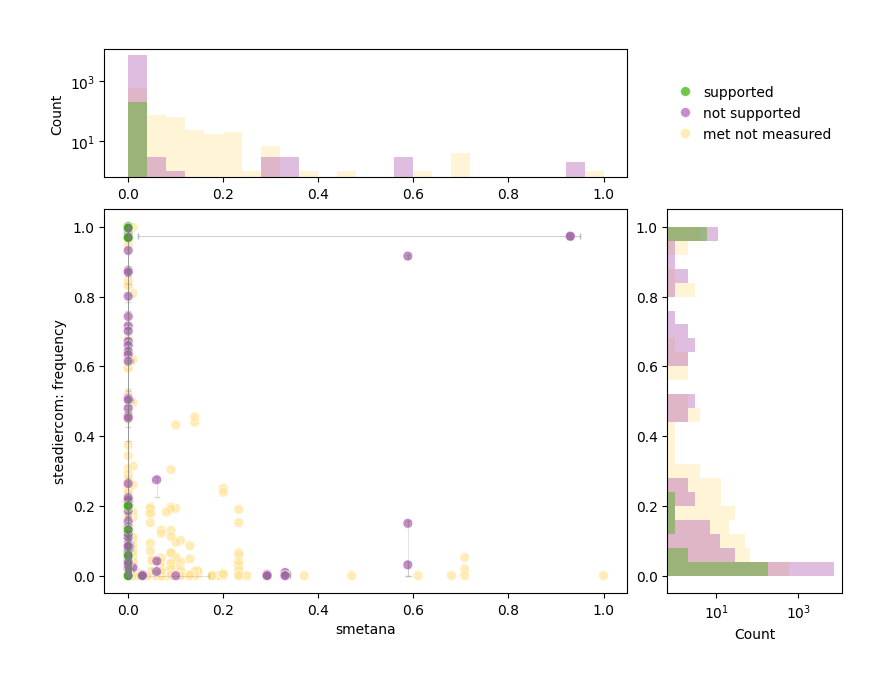

In [21]:
plot_df = df_merge.sort_values("experimental_support")

fig = plt.figure(constrained_layout=True,figsize=(8,6))
spec = gridspec.GridSpec(ncols=4, nrows=4, figure=fig)

ax1 = fig.add_subplot(spec[1:, 3])
ax2 = fig.add_subplot(spec[0, :3])
ax3 = fig.add_subplot(spec[1:, :3])
ax_legend = fig.add_subplot(spec[0,3])

hue_order = plot_df.experimental_support.sort_values(ascending=False).unique()


ax3 = sns.scatterplot(
    plot_df,
    x="smetana_median",#"smetana",
    y="steadiercom_median",#"frequency",
    hue="experimental_support", #"overlap",
    s=50,
    palette=cmap_dict_overlap,
    hue_order=hue_order,
    alpha=0.7,
    legend=True,
    ax=ax3,
    zorder=1,
)

plot_df_reduced = plot_df.query("experimental_support != 'met not measured'").copy()
y_errors = [plot_df_reduced["steadiercom_median"] - plot_df_reduced["steadiercom_q25"], plot_df_reduced["steadiercom_q75"] - plot_df_reduced["steadiercom_median"]]
x_errors = [plot_df_reduced["smetana_median"] - plot_df_reduced["smetana_q25"], plot_df_reduced["smetana_q75"] - plot_df_reduced["smetana_median"]]

ax3.errorbar(
    x=plot_df_reduced["smetana_median"], 
    y=plot_df_reduced["steadiercom_median"], 
    yerr=y_errors, 
    xerr=x_errors,
    fmt="none",
    color="gray",
    alpha=0.3,
    capsize=2,
    zorder=2,
)

ax3.set_ylabel("steadiercom: frequency")
ax3.set_xlabel("smetana")

ax1 = sns.histplot(plot_df, 
                   y="steadiercom_median",
                    hue="experimental_support",
                    hue_order=hue_order,
                    palette=cmap_dict_overlap,
                    ax=ax1, 
                    bins=25, 
                    alpha=0.4,
                    legend=False)
ax1.set_xscale("log")
ax1.set_ylabel("")

ax2 = sns.histplot(plot_df,
                   x="smetana_median",
                   hue="experimental_support",
                   hue_order=hue_order,
                   palette=cmap_dict_overlap,
                   ax=ax2,
                   bins=25,
                   alpha=0.4,
                   legend=False,
                   )
ax2.set_yscale("log")
ax2.set_xlabel("")

handles, labels = ax3.get_legend_handles_labels()

ax_legend.legend(handles=handles, loc='center')
ax_legend.set_axis_off()
if ax3.get_legend() is not None:
    ax3.get_legend().remove()


In [22]:
df_merge = merge_metabolomics(
    merged_sim.query("community == 'NONE'"),
    signal_exp_df,
    metid2metname,
    []
)

(<Figure size 1200x800 with 4 Axes>,
 (<Axes: ylabel='Counts'>,
  <Axes: ylabel='Unique Counts'>,
  <Axes: title={'center': 'SteadierCom - frequency'}, ylabel='frequency'>,
  <Axes: title={'center': 'SMETANA'}, xlabel='Metabolite class', ylabel='SMETANA'>))

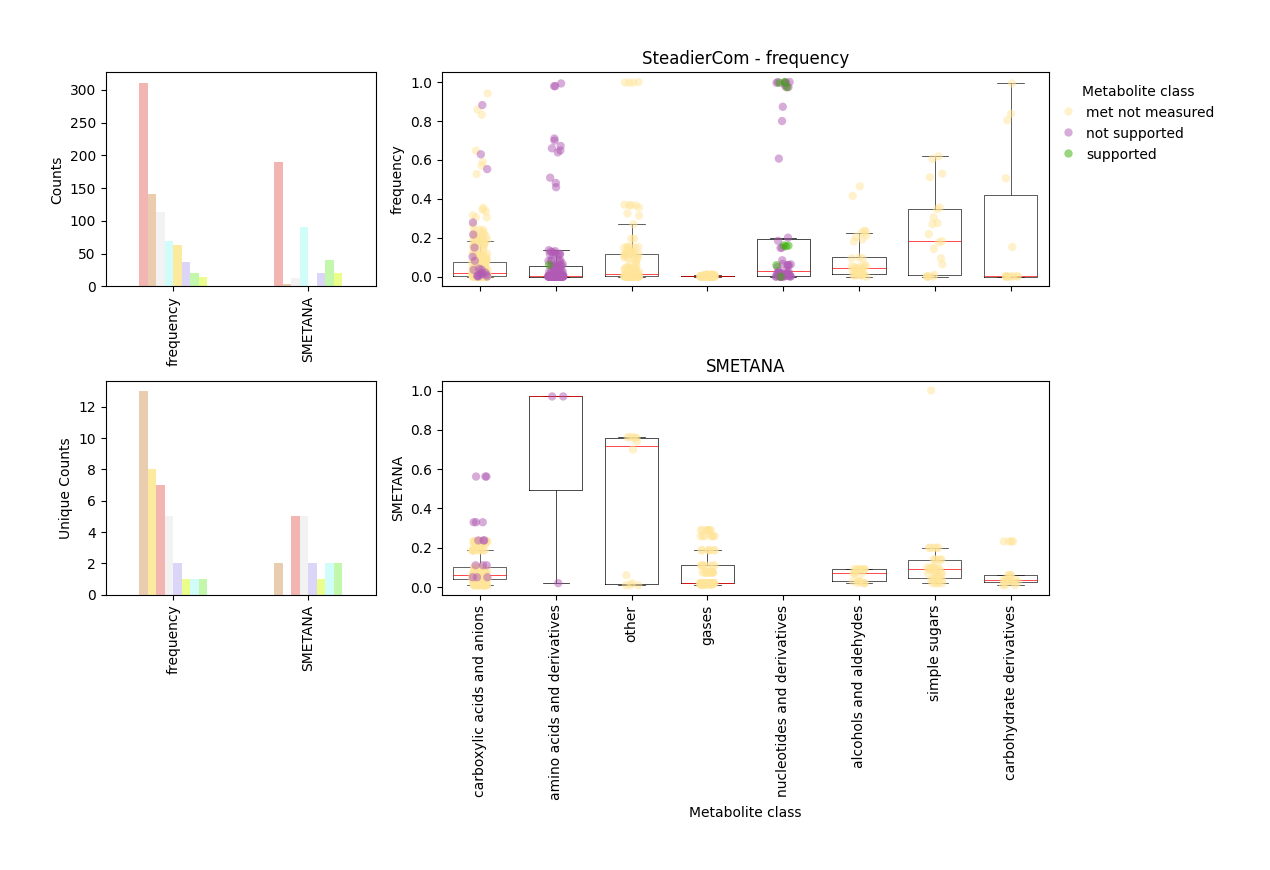

In [23]:
plot_violin(df_merge,threshold=1e-6)

### Overall statistics

In [24]:
def pos_neg_class_exp(metabolomics, metid2metname,exp_thresh=1):
    exp_triplets_df  = make_metabolomics_triplets(metabolomics, exp_thresh=exp_thresh)
   
    metname_translate_AGORA = metid2metname.values()
    n_exp_thresh = (
        exp_triplets_df
        .query("compound_name in @metname_translate_AGORA")
        .groupby("exp_interact")
        .size()
        )

    return {
        "Negative (No interaction)": n_exp_thresh[False],
        "Positive (Inferred interaction)": n_exp_thresh[True],
        
    }

def overlap_statistic(simulation_dict,exp_thresh=1):

    smetana_results = simulation_dict["smetana"]["SMETANA"].copy()
    steadiercom_results = simulation_dict["steadiercom"]["SteadierCom - Fixed growth & abundance"].copy()

    exp_triplets_df  = make_metabolomics_triplets(metabolomics, exp_thresh=exp_thresh)
    
    smetana_merged_sim_exp = merge_metabolomics(smetana_results,exp_triplets_df,metid2metname,[])
    smetana_stats = smetana_merged_sim_exp[~smetana_merged_sim_exp["smetana"].isna()].groupby("experimental_support").size()

    steadiercom_merged_sim_exp = merge_metabolomics(steadiercom_results,exp_triplets_df,metid2metname,[])
    steadiercom_stats = steadiercom_merged_sim_exp[~steadiercom_merged_sim_exp["frequency"].isna()].groupby("experimental_support").size()

    return steadiercom_stats, smetana_stats


#### Calculate overlap

In [25]:
res_exp_dict = {}
res_overlap_steadiercom = {}
res_overlap_smetana = {}
for exp_thresh in [round(value,2) for value in np.linspace(0.1,1.1, num=6)]:
    res_exp_dict[exp_thresh] = pos_neg_class_exp(metabolomics, metid2metname,exp_thresh=exp_thresh)

    steadiercom_stats,smetana_stats = overlap_statistic(simulation_dict, exp_thresh=exp_thresh)
    res_overlap_steadiercom[exp_thresh] = steadiercom_stats
    res_overlap_smetana[exp_thresh] = smetana_stats

NameError: name 'simulation_dict' is not defined

In [ ]:

stats = pd.DataFrame(res_exp_dict).T.reset_index().rename(columns={"index":"exp_thresh"}).melt(id_vars=["exp_thresh"], var_name="class", value_name="count")

steadiercom_stats = pd.DataFrame(res_overlap_steadiercom).T.reset_index().rename(columns={"index":"exp_thresh"})
steadiercom_stats = steadiercom_stats.melt(id_vars=["exp_thresh"], var_name="overlap", value_name="count")
smetana_stats = pd.DataFrame(res_overlap_smetana).T.reset_index().rename(columns={"index":"exp_thresh"})
smetana_stats = smetana_stats.melt(id_vars=["exp_thresh"], var_name="overlap", value_name="count")

[INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
[INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


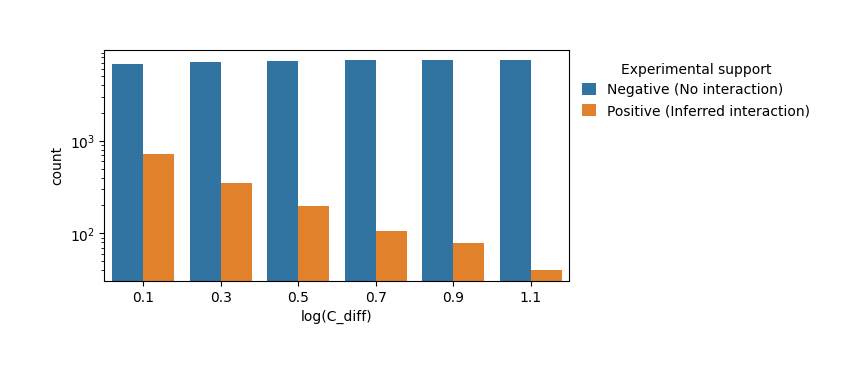

In [ ]:

fig,ax = plt.subplots(1,1,figsize=(6,3))
ax = sns.barplot(data=stats,x="exp_thresh", y="count", hue="class")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1.0, 1.0),title="Experimental support")
ax.set_xlabel("log(C_diff)")
ax.set_yscale("log")

#### Overlap between SMETANA and SteadierCom

Text(0, 0.5, 'Count of interactions')

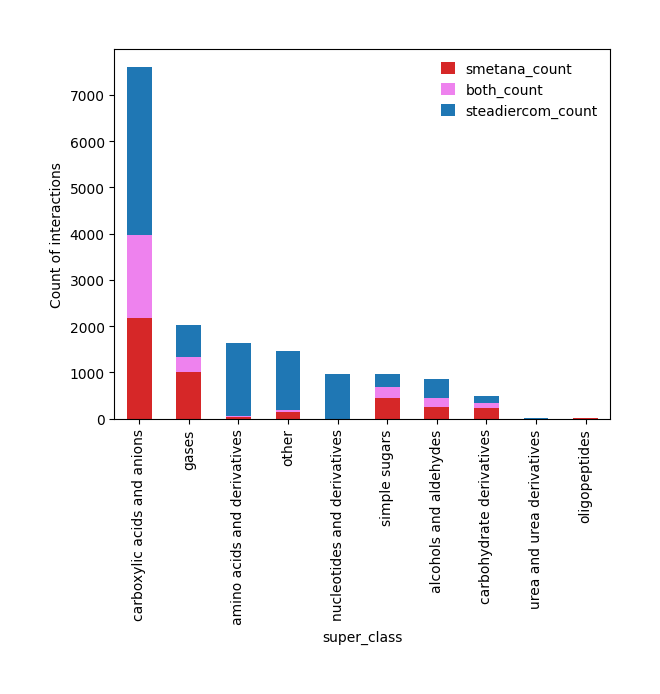

In [ ]:
mask_both = merged_sim[["smetana", "frequency"]].notna().all(axis=1)

result = merged_sim.groupby("super_class").agg(
    smetana_count=("smetana", "count"),
    steadiercom_count=("frequency", "count"),
    both_count=("smetana", lambda x: mask_both.loc[x.index].sum())
)

order_mets = result.sum(axis=1).sort_values(ascending=False).index
order_groups = ["smetana_count","both_count","steadiercom_count"]
ax = result.loc[order_mets,order_groups].plot.bar(stacked=True,color=["tab:red","violet","tab:blue"])
ax.set_ylabel("Count of interactions")

Text(0, 0.5, 'Count of interactions')

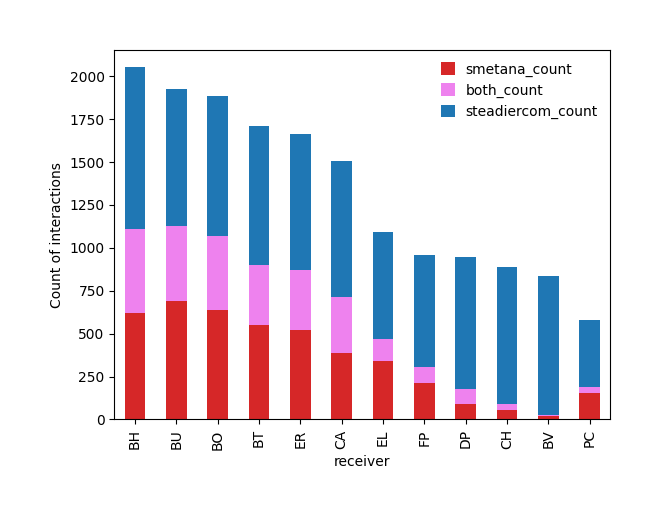

In [ ]:
mask_both = merged_sim[["smetana", "frequency"]].notna().all(axis=1)

result = merged_sim.groupby("receiver").agg(
    smetana_count=("smetana", "count"),
    steadiercom_count=("frequency", "count"),
    both_count=("smetana", lambda x: mask_both.loc[x.index].sum())
)

order_mets = result.sum(axis=1).sort_values(ascending=False).index
order_groups = ["smetana_count","both_count","steadiercom_count"]
ax = result.loc[order_mets,order_groups].plot.bar(stacked=True,color=["tab:red","violet","tab:blue"])
ax.set_ylabel("Count of interactions")


## SteadierCom prediction of competition and cooperation in comparison to predicted gLV coefficients

#### Import gLV coefficients

#### Calculate the score for competition and cooperation

In [ ]:
df_merged_unfiltered1 = process_simulation_results(steadiercom_results_all, signal_exp, method_comp=1)
df_merged_unfiltered2 = process_simulation_results(steadiercom_results_all, signal_exp, method_comp=2)
df_merged_unfiltered3 = process_simulation_results(steadiercom_results_all, signal_exp, method_comp=3)

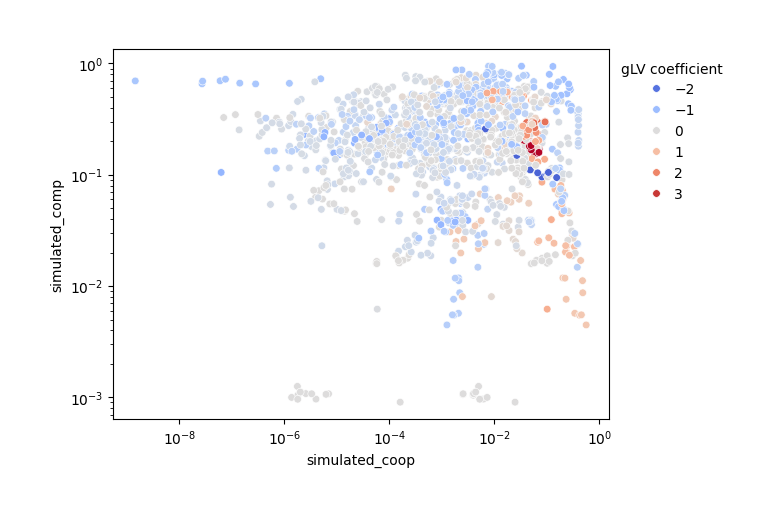

In [ ]:
df_merged = df_merged_unfiltered2.copy()
values = df_merged["experimental"]

# Normalize colors so that 0 is the center
norm = TwoSlopeNorm(
    vmin=values.min(),
    vcenter=0,
    vmax=values.max()
)
palette=mpl.colormaps["coolwarm"]

fig,ax = plt.subplots(1,1)

sns.scatterplot(ax=ax,
                data=df_merged,
                x="simulated_coop",
                y="simulated_comp",
                hue="experimental",
                palette=palette,
                hue_norm=norm,
                s=30
)
ax.set_xscale("log")
ax.set_yscale("log")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1.0, 1.0),title="gLV coefficient")

### Plot of distribution around median 

In [ ]:
df_median_stats = df_merged_unfiltered2.dropna().reset_index().groupby(["member_second","member_main"]).agg(coop_median = ("simulated_coop","median"),
                                                                                 coop_q25 = ("simulated_coop", lambda x: np.percentile(x, 25)),
                                                                                 coop_q75 = ("simulated_coop", lambda x: np.percentile(x, 75)),
                                                                                 comp_median = ("simulated_comp","median"),
                                                                                 comp_q25 = ("simulated_comp", lambda x: np.percentile(x, 25)),
                                                                                 comp_q75 = ("simulated_comp", lambda x: np.percentile(x, 75)),
                                                                                 experimental = ("experimental","mean")
                                                                                )

In [ ]:
def plot_interactions_median(df_merged,title=""):

    # Column used for the color gradient
    values = df_merged["experimental"]

    # Normalize colors so that 0 is the center
    norm = TwoSlopeNorm(
        vmin=-3,
        vcenter=0,
        vmax=3
    )
    palette=mpl.colormaps["coolwarm"]

    fig = plt.figure(figsize=(11,8))

    gs = GridSpec(2, 2, width_ratios=[1, 2], height_ratios=[2, 1],)
    ax1 = fig.add_subplot(gs[0])
    ax2 = fig.add_subplot(gs[1])
    ax3 = fig.add_subplot(gs[2])
    ax4 = fig.add_subplot(gs[3])

    sns.scatterplot(data=df_merged, 
                    x="coop_median", 
                    y="comp_median", 
                    hue="experimental", 
                    palette=palette,
                    hue_norm=norm,
                    s=30,
                    alpha=1,
                    ax=ax2)
    y_errors = [df_merged["comp_median"] - df_merged["comp_q25"], df_merged["comp_q75"] - df_merged["comp_median"]]
    x_errors = [df_merged["coop_median"] - df_merged["coop_q25"], df_merged["coop_q75"] - df_merged["coop_median"]]
    ax2.errorbar(
        x=df_merged["coop_median"], 
        y=df_merged["comp_median"], 
        yerr=y_errors, 
        xerr=x_errors,
        fmt="none",
        color="gray",
        alpha=0.3,
    )

    sns.move_legend(ax2, "upper left", bbox_to_anchor=(1.0, 1.0),title="gLV coefficient")

    for ax,comp_coop in zip([ax1, ax4], ["comp_median", "coop_median"]):

        if comp_coop=="comp_median":
            x,y ="exp_categories",comp_coop
        else:
            x,y =comp_coop,"exp_categories"

        sns.violinplot(df_merged,x=x,y=y,hue="exp_categories",ax=ax,palette="coolwarm",cut=0,alpha=0.5,linecolor="gray",inner_kws=dict(box_width=8, whis_width=1,alpha=0.8),zorder=0,legend=(comp_coop=="coop_median"))
        sns.stripplot(df_merged,x=x,y=y,hue="exp_categories",palette="coolwarm",ax=ax,alpha=0.5,linewidth=0.5,edgecolor="gray",size=4,jitter=0.2,zorder=1)

    sns.move_legend(ax4, "upper left", bbox_to_anchor=(1.0, 1.0),title="gLV coefficient (categorical)")

    ax1.set_ylabel("Competition")
    ax4.set_xlabel("Cooperation")

    sns.kdeplot(df_merged,
                x="experimental",
                ax=ax3
    )
    x, y = ax3.get_lines()[0].get_data()
    segments = np.array([x[:-1], y[:-1], x[1:], y[1:]]).T.reshape(-1, 2, 2)
    lc = LineCollection(segments, cmap='coolwarm', norm=norm)
    lc.set_array(x[:-1])
    lc.set_linewidth(2)
    ax3.get_lines()[0].remove()
    line = ax3.add_collection(lc)
    ax3.set_xlabel("gLV coefficient")
    
    ax2.set_xlabel("")
    ax2.set_ylabel("")

    ax1.set_xlabel("")
    ax4.set_ylabel("")

    fig.suptitle(title, fontsize=14)

    plt.show()

/var/folders/mc/1rm74nkd4s78l46281nyt5wm0000gn/T/ipykernel_15450/1978907349.py:52: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.violinplot(df_merged,x=x,y=y,hue="exp_categories",ax=ax,palette="coolwarm",cut=0,alpha=0.5,linecolor="gray",inner_kws=dict(box_width=8, whis_width=1,alpha=0.8),zorder=0,legend=(comp_coop=="coop_median"))
/var/folders/mc/1rm74nkd4s78l46281nyt5wm0000gn/T/ipykernel_15450/1978907349.py:53: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(df_merged,x=x,y=y,hue="exp_categories",palette="coolwarm",ax=ax,alpha=0.5,linewidth=0.5,edgecolor="gray",size=4,jitter=0.2,zorder=1)
/var/folders/mc/1rm74nkd4s78l46281nyt5wm0000gn/T/ipykernel_15450/1978907349.py:52: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.violinplot(df_mer

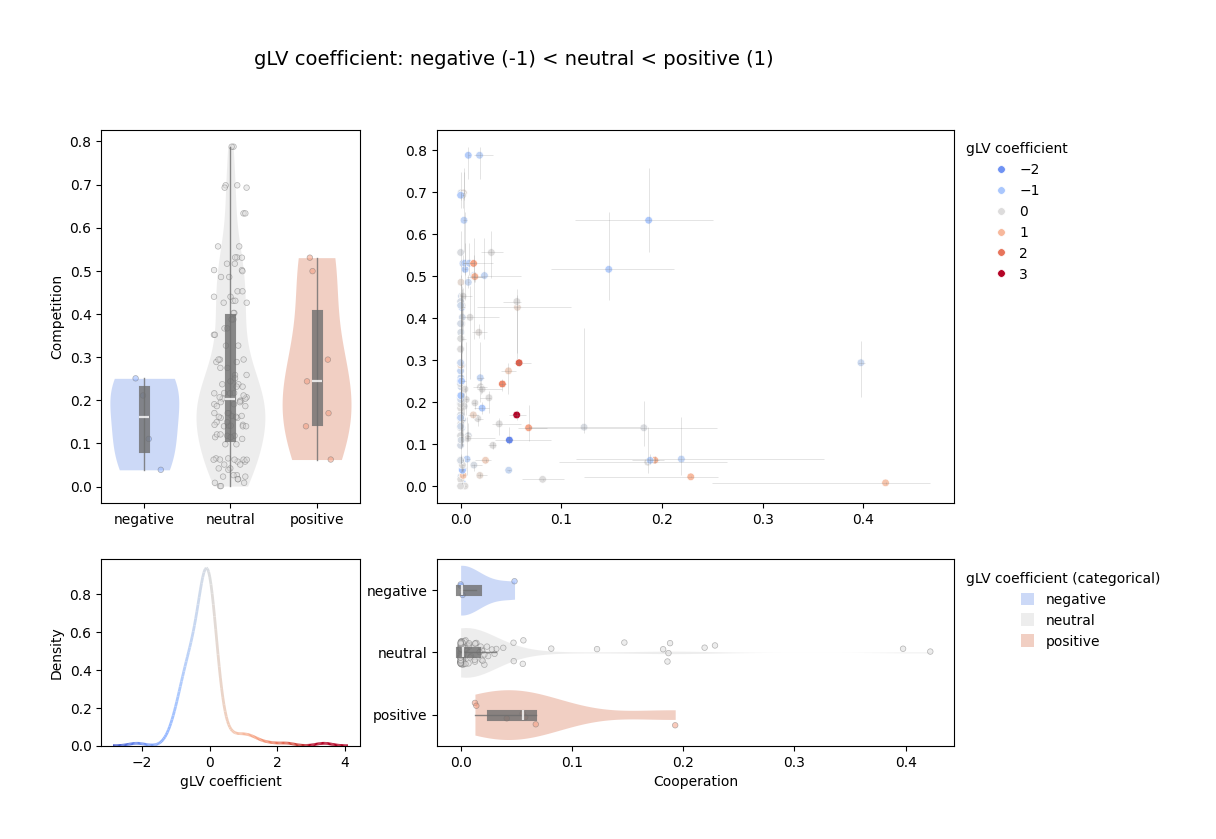

In [ ]:
df_merged = prepare_data(df_median_stats, glv_cutoff=1)
plot_interactions_median(df_merged,title="gLV coefficient: negative (-1) < neutral < positive (1)")

/var/folders/mc/1rm74nkd4s78l46281nyt5wm0000gn/T/ipykernel_15450/1978907349.py:52: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.violinplot(df_merged,x=x,y=y,hue="exp_categories",ax=ax,palette="coolwarm",cut=0,alpha=0.5,linecolor="gray",inner_kws=dict(box_width=8, whis_width=1,alpha=0.8),zorder=0,legend=(comp_coop=="coop_median"))
/var/folders/mc/1rm74nkd4s78l46281nyt5wm0000gn/T/ipykernel_15450/1978907349.py:53: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(df_merged,x=x,y=y,hue="exp_categories",palette="coolwarm",ax=ax,alpha=0.5,linewidth=0.5,edgecolor="gray",size=4,jitter=0.2,zorder=1)
/var/folders/mc/1rm74nkd4s78l46281nyt5wm0000gn/T/ipykernel_15450/1978907349.py:52: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.violinplot(df_mer

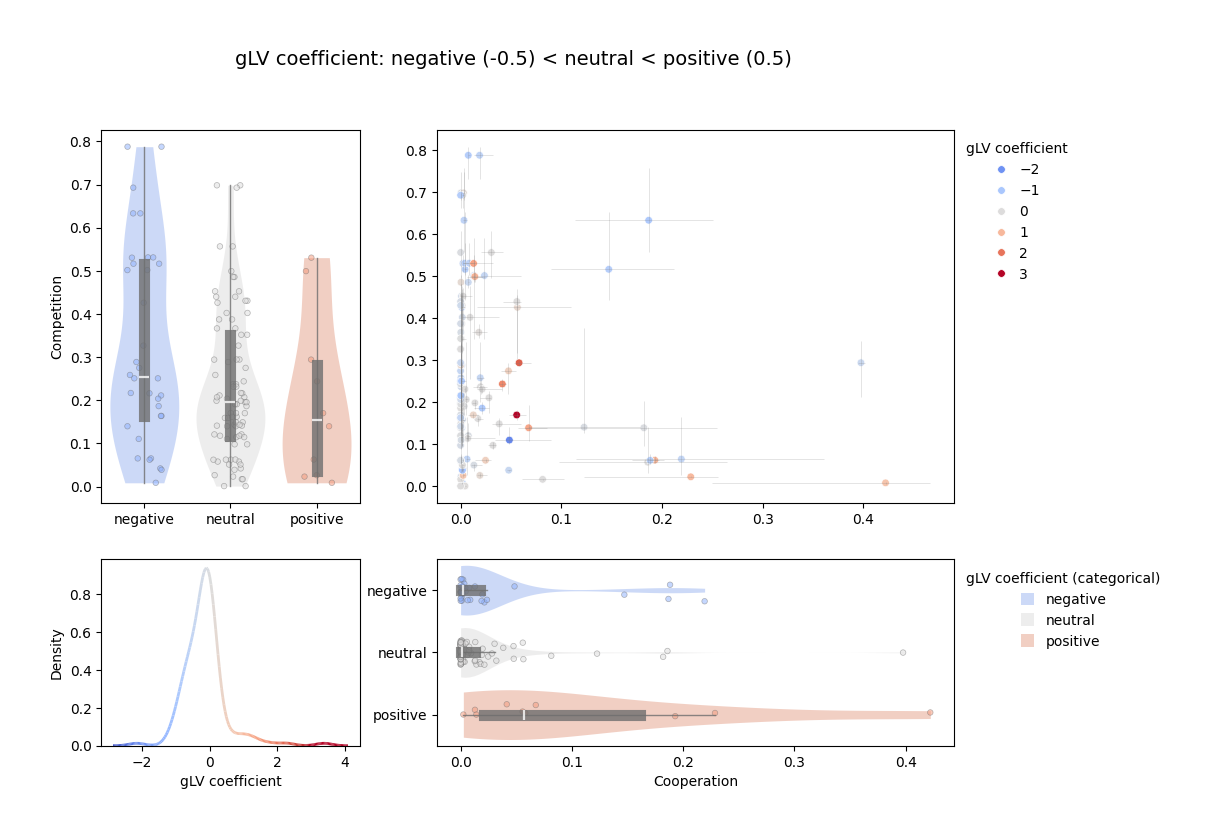

In [ ]:
df_merged = prepare_data(df_median_stats, glv_cutoff=0.5)
plot_interactions_median(df_merged,title="gLV coefficient: negative (-0.5) < neutral < positive (0.5)")

# Abundance

In [ ]:
exp_abundance_df = venturelli2018_abund.load_experimental_results()

In [ ]:
cmap = ['#a6cee3','#1f78b4', '#b2df8a', '#33a02c', '#fb9a99','#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#6a3d9a', '#ffff99', '#b15928']
member_colors = dict(zip(exp_abundance_df.columns,cmap))

In [ ]:

def plot_scatter_steadiercom(joined_spec,ax,title,legend=None):
    joined_mean = joined_spec.groupby(["community","member"]).agg({'relative_abundance_sim':'mean','relative_abundance_exp':'mean'})\
                            .rename(columns={'relative_abundance_sim':'SteadierCom relative abundance','relative_abundance_exp':'Experimental relative abundance'})

    stat = kendalltau(joined_mean["Experimental relative abundance"],joined_mean["SteadierCom relative abundance"])
    g = sns.lineplot(joined_spec,
                x="relative_abundance_exp",
                y="relative_abundance_sim",
                hue="member",
                marker="o",
                markersize=10,
                linestyle="",
                err_style="bars",
                errorbar="ci",
                palette=member_colors,
                legend=legend,
                ax=ax)
    
    ax.text(0.1, 0.8, f"Kendalls tau={stat.correlation:.2f} \n p-value={stat.pvalue:.2e}", transform=ax.transAxes)
    ax.set_title(title)
    return ax


def plot_scatter_steadycom(joined_spec,ax,title,legend=None):
    
    stat = kendalltau(joined_spec["relative_abundance_exp"],joined_spec["relative_abundance_sim"])
    g = sns.scatterplot(joined_spec,
                x="relative_abundance_exp", 
                y="relative_abundance_sim",
                hue="member",
                marker="o",
                s=80,
                linestyle="",
                palette=member_colors,
                legend=legend,
                ax=ax)
    
    ax.text(0.1, 0.8, f"Kendalls tau={stat.correlation:.2f} \n p-value={stat.pvalue:.2e}", transform=ax.transAxes)
    ax.set_title(title)
    return ax


### SteadierCom

**Load and process data**

In [ ]:
# Load experimental results

exp_abundance_df_reshaped = exp_abundance_df.stack().reset_index()
exp_abundance_df_reshaped.rename(columns={0:"relative_abundance"}, inplace=True)

# Load SteadyCom results
_, _, steadycom_abundance_df = venturelli2018_abund.load_simulation_results()

# Load SteadierCom results for all communities
abundance_list = []
for file in os.listdir("../output/Venturelli2018/results_steadiercom/results_growth/"):
    if file.endswith("_abundance.tsv"):
        abundance_list.append(pd.read_csv(f"../output/Venturelli2018/results_steadiercom/results_growth/{file}",sep="\t"))
steadiercom_abundance_df = pd.concat(abundance_list) # Join all dataframes
# Map member names to their initials
steadiercom_abundance_df.member = steadiercom_abundance_df.member.map(lambda x: x.split("_")[0][0].upper()+x.split("_")[1][0].upper())
# Fill missing values for absent members with zero abundance
steadiercom_abundance_df = (
    steadiercom_abundance_df.pivot_table(index=["community","sample"], columns='member', values='relative_abundance', fill_value=0)
    .stack()
    .reset_index()
)
steadiercom_abundance_df.rename(columns={0:"relative_abundance"}, inplace=True)
# Merge simulated and experimental data
joined_spec = pd.merge(steadiercom_abundance_df, exp_abundance_df_reshaped, on=["community","member"], suffixes=("_sim","_exp"))

**Plot**

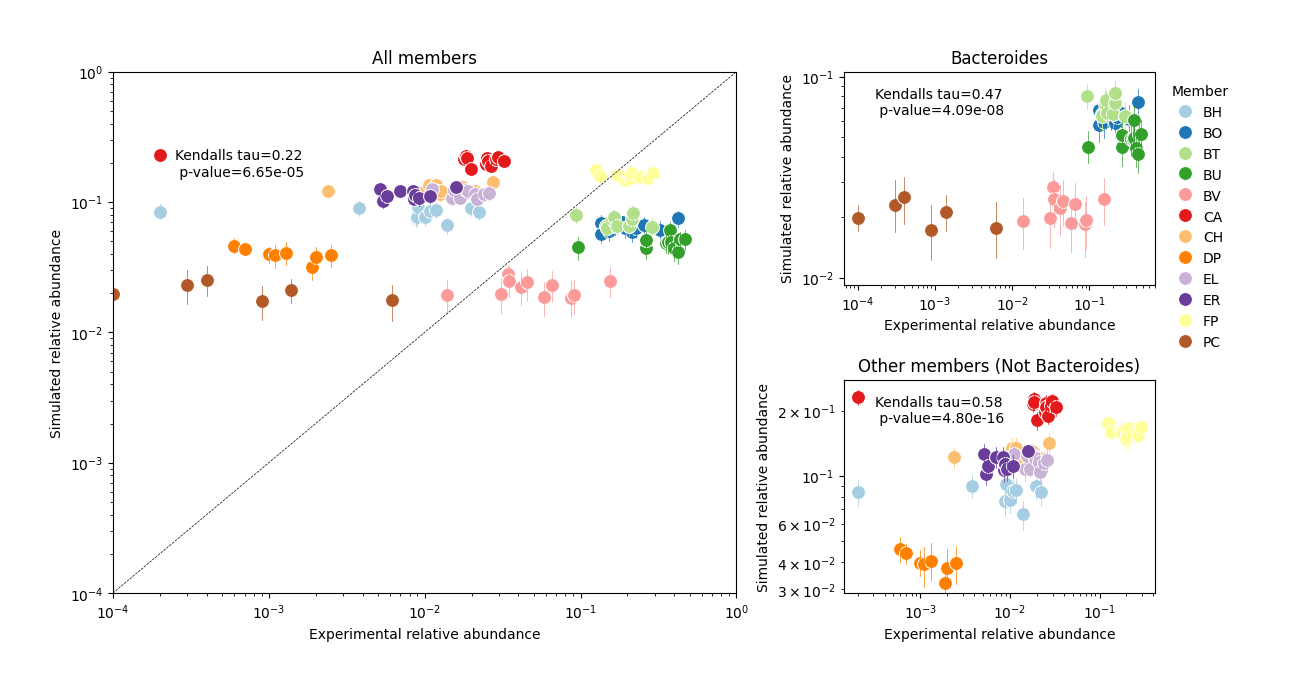

In [41]:
fig = plt.figure(figsize=(12, 6), constrained_layout=True)

gs = fig.add_gridspec(
    2, 7,
    width_ratios=[1, 1, 1, 1, 1, 1, 0.5],
)

ax1 = fig.add_subplot(gs[:, :4])
ax2 = fig.add_subplot(gs[0, 4:6])
ax3 = fig.add_subplot(gs[1, 4:6])
ax_leg = fig.add_subplot(gs[:, 6])

ax1 = plot_scatter_steadiercom(
    joined_spec,
    ax1,
    "All members",
    legend=True
)
ax1.axline((0, 0), slope=1, color='black', linestyle='--')
ax1.set_ylim(1e-4,1)
ax1.set_xlim(1e-4,1)

bacteroides = ["BO","BT","BU","BV","PC"]
not_bacteroides = [m for m in joined_spec.member.unique() if m not in bacteroides]
joined_spec_new = joined_spec[joined_spec.member.isin(bacteroides)].copy()
ax2 = plot_scatter_steadiercom(joined_spec_new,
                               ax2,
                               "Bacteroides")


joined_spec_new = joined_spec[~joined_spec.member.isin(bacteroides)].copy()
ax3 = plot_scatter_steadiercom(joined_spec_new,
                               ax3,
                               "Other members (Not Bacteroides)")


# move legend from ax1 to dedicated legend axis

handles, labels = ax1.get_legend_handles_labels()
if ax1.legend_ is not None:
    ax1.legend_.remove()

ax_leg.axis("off")
ax_leg.legend(handles, labels, loc="upper right", title="Member", frameon=False)


for ax in (ax1, ax2, ax3):
    ax.set_yscale("log")
    ax.set_xscale("log")
    ax.set_ylabel("Simulated relative abundance")
    ax.set_xlabel("Experimental relative abundance")
    #ax.tick_params(labelbottom=False, labelleft=False)


### SteadierCom/SteadyCom (without allocation constraints - but with sampling)

**Load and process data**

In [42]:
# Load experimental results

exp_abundance_df_reshaped = exp_abundance_df.stack().reset_index()
exp_abundance_df_reshaped.rename(columns={0:"relative_abundance"}, inplace=True)

# Load SteadyCom results
_, _, steadycom_abundance_df = venturelli2018_abund.load_simulation_results()

# Load SteadierCom results for all communities
abundance_list = []
for file in os.listdir("../output/Venturelli2018/results_steadiercom_no_proteome/results_growth/"):
    if file.endswith("_abundance.tsv"):
        abundance_list.append(pd.read_csv(f"../output/Venturelli2018/results_steadiercom_no_proteome/results_growth/{file}",sep="\t"))
steadiercom_abundance_df = pd.concat(abundance_list) # Join all dataframes
# Map member names to their initials
steadiercom_abundance_df.member = steadiercom_abundance_df.member.map(lambda x: x.split("_")[0][0].upper()+x.split("_")[1][0].upper())
# Fill missing values for absent members with zero abundance
steadiercom_abundance_df = (
    steadiercom_abundance_df.pivot_table(index=["community","sample"], columns='member', values='relative_abundance', fill_value=0)
    .stack()
    .reset_index()
)
steadiercom_abundance_df.rename(columns={0:"relative_abundance"}, inplace=True)
# Merge simulated and experimental data
joined_spec = pd.merge(steadiercom_abundance_df, exp_abundance_df_reshaped, on=["community","member"], suffixes=("_sim","_exp"))

**Plot**

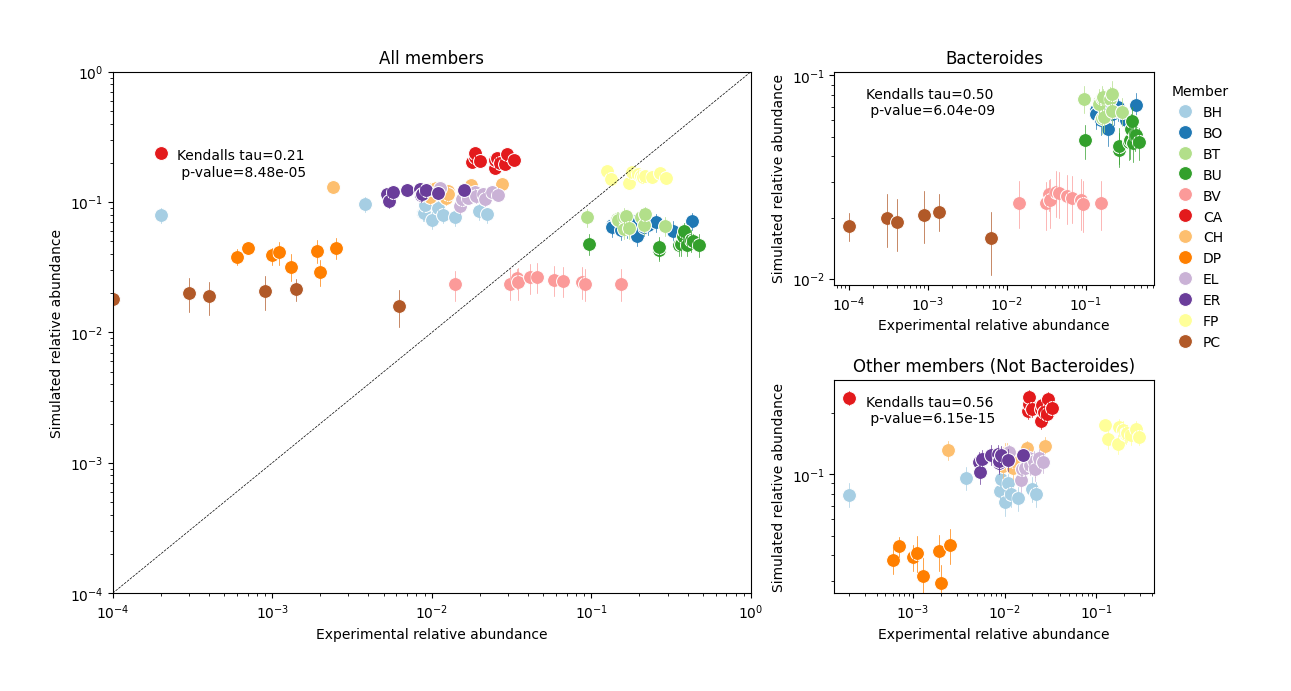

In [43]:
fig = plt.figure(figsize=(12, 6), constrained_layout=True)

gs = fig.add_gridspec(
    2, 7,
    width_ratios=[1, 1, 1, 1, 1, 1, 0.5],
)

ax1 = fig.add_subplot(gs[:, :4])
ax2 = fig.add_subplot(gs[0, 4:6])
ax3 = fig.add_subplot(gs[1, 4:6])
ax_leg = fig.add_subplot(gs[:, 6])

ax1 = plot_scatter_steadiercom(
    joined_spec,
    ax1,
    "All members",
    legend=True
)
ax1.axline((0, 0), slope=1, color='black', linestyle='--')
ax1.set_ylim(1e-4,1)
ax1.set_xlim(1e-4,1)

bacteroides = ["BO","BT","BU","BV","PC"]
not_bacteroides = [m for m in joined_spec.member.unique() if m not in bacteroides]
joined_spec_new = joined_spec[joined_spec.member.isin(bacteroides)].copy()
ax2 = plot_scatter_steadiercom(joined_spec_new,
                               ax2,
                               "Bacteroides")


joined_spec_new = joined_spec[~joined_spec.member.isin(bacteroides)].copy()
ax3 = plot_scatter_steadiercom(joined_spec_new,
                               ax3,
                               "Other members (Not Bacteroides)")


# move legend from ax1 to dedicated legend axis

handles, labels = ax1.get_legend_handles_labels()
if ax1.legend_ is not None:
    ax1.legend_.remove()

ax_leg.axis("off")
ax_leg.legend(handles, labels, loc="upper right", title="Member", frameon=False)


for ax in (ax1, ax2, ax3):
    ax.set_yscale("log")
    ax.set_xscale("log")
    ax.set_ylabel("Simulated relative abundance")
    ax.set_xlabel("Experimental relative abundance")
    #ax.tick_params(labelbottom=False, labelleft=False)


### SteadyCom

**Load and process data**

In [44]:
steadycom_abundance_reshaped = (
    pd.melt((steadycom_abundance_df.fillna(0).rename_axis("community").reset_index()),
        id_vars="community",
        var_name="member",
        value_name="relative_abundance")
        )
# Merge simulated and experimental data
joined_spec = pd.merge(steadycom_abundance_reshaped, exp_abundance_df_reshaped, on=["community","member"], suffixes=("_sim","_exp"))

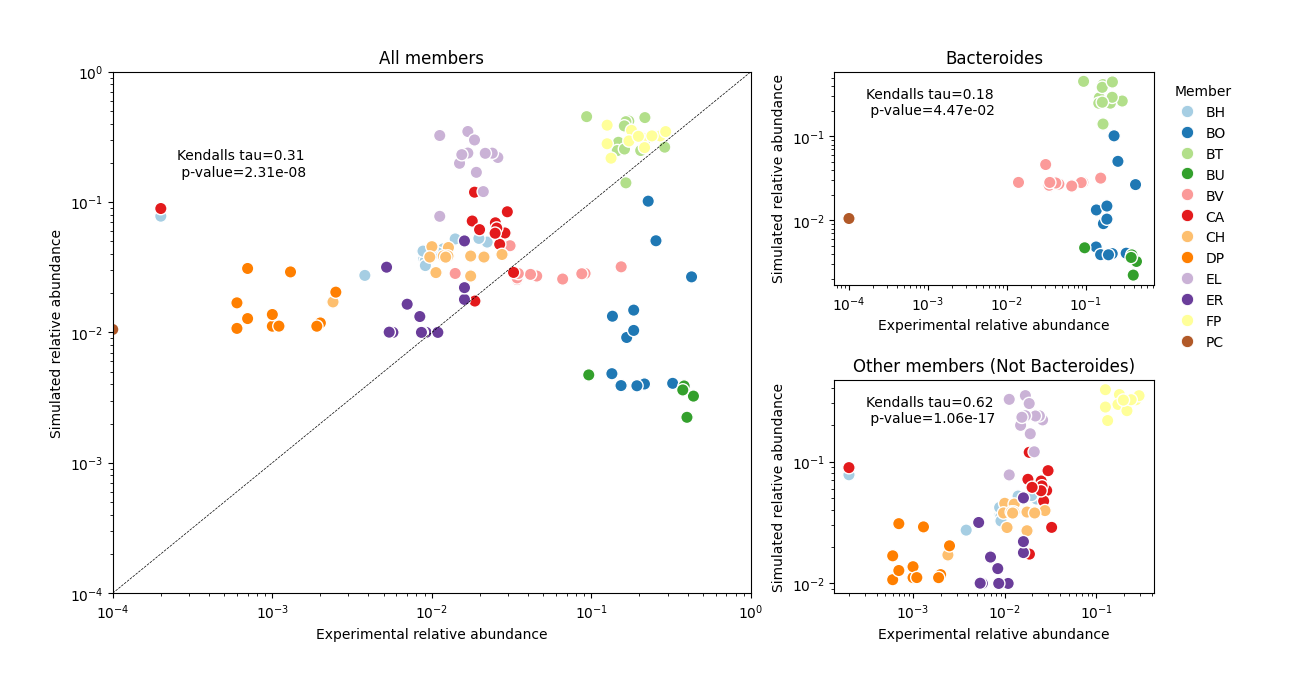

In [45]:
fig = plt.figure(figsize=(12, 6), constrained_layout=True)

gs = fig.add_gridspec(
    2, 7,
    width_ratios=[1, 1, 1, 1, 1, 1, 0.5],

)

ax1 = fig.add_subplot(gs[:, :4])
ax2 = fig.add_subplot(gs[0, 4:6])
ax3 = fig.add_subplot(gs[1, 4:6])
ax_leg = fig.add_subplot(gs[:, 6])

ax1 = plot_scatter_steadycom(joined_spec,
                               ax1,
                               "All members",
                               legend=True)
ax1.axline((0, 0), slope=1, color='black', linestyle='--')
ax1.set_ylim(1e-4,1)
ax1.set_xlim(1e-4,1)

bacteroides = ["BO","BT","BU","BV","PC"]
not_bacteroides = [m for m in joined_spec.member.unique() if m not in bacteroides]
joined_spec_new = joined_spec[joined_spec.member.isin(bacteroides)].copy()
ax2 = plot_scatter_steadycom(joined_spec_new,
                               ax2,
                               "Bacteroides")

joined_spec_new = joined_spec[~joined_spec.member.isin(bacteroides)].copy()
ax3 = plot_scatter_steadycom(joined_spec_new,
                               ax3,
                               "Other members (Not Bacteroides)")


# move legend from ax1 to dedicated legend axis
handles, labels = ax1.get_legend_handles_labels()
if ax1.legend_ is not None:
    ax1.legend_.remove()

ax_leg.axis("off")
ax_leg.legend(handles, labels, loc="upper left", title="Member", frameon=False)


for ax in (ax1, ax2, ax3):
    ax.set_yscale("log")
    ax.set_xscale("log")
    ax.set_ylabel("Simulated relative abundance")
    ax.set_xlabel("Experimental relative abundance")


<Axes: xlabel='member'>

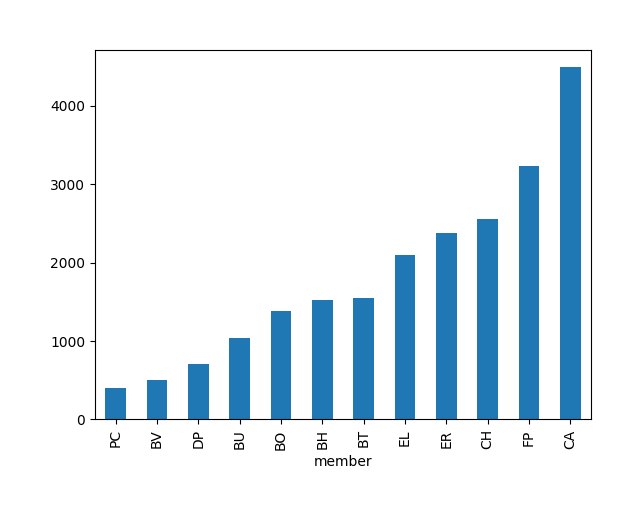

In [46]:
steadiercom_abundance_df.query("relative_abundance > 0.99").groupby("member")["relative_abundance"].count().sort_values().plot(kind="bar")